In [30]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import time
import os
import pandas as pd

In [2]:
# path for train, test and valid directory

train_dir = 'D:\\download\\100 bird species\\100-bird-species\\train'
test_dir = 'D:\\download\\100 bird species\\100-bird-species\\test'
valid_dir = 'D:\\download\\100 bird species\\100-bird-species\\valid'

# classes of birds
classes=os.listdir(test_dir)

# making dictionary such that if a number(code) is given between 0 to 184 , i can tell class of bird
# and if class is given , i can tell a number code for corresponding class
label_code = {}
code_label = {}
a = 0
for i in classes:
    label_code.update({i:a})
    code_label.update({a:i})
    a+=1
    

In [3]:
# using generator so that model use less ram of laptop

generator = ImageDataGenerator(horizontal_flip = True, vertical_flip = True,
                               width_shift_range = 0.1,zoom_range = 0.1,height_shift_range = 0.1,rescale = 1/255)

# Training data
train_data = generator.flow_from_directory(train_dir, target_size=(224,224),
                                                 batch_size=64, 
                                                 class_mode="categorical")

# Testing data
test_data = generator.flow_from_directory(test_dir, target_size=(224,224),
                                                 batch_size=64,shuffle=False,
                                               class_mode="categorical")

# Validation data
valid_data = generator.flow_from_directory(valid_dir, target_size=(224,224),
                                                 batch_size=64,shuffle=False,
                                                  class_mode="categorical")

Found 25171 images belonging to 185 classes.
Found 925 images belonging to 185 classes.
Found 925 images belonging to 185 classes.


In [4]:
# function used if we want to run model training for more required epoch to reach optimum accuracy
# this will ask number of epoch we want to run more
# if we dnt want to run more, press n and training will be stopped

def run_more():
    while True :
        x = input('For more training, Input number of epoch (+ve integer) for more training OR press " N " to stop\n')
        if x.upper() == 'N':
            print('\033[1m','-----------End Of Training-----------','\033[0m \n')
            
            return [False,0]
        else :
            try:
                # this will help if input is not integar, function will ask again if input is not integar
                if int(x) >= 0 :
                    return [True,int(x)]
                else:
                    print('Please provide positive integar\n')
                
            except ValueError:
                print('\033[1m','incorrect input\n','\033[0m \n')

In [5]:
# Our input feature map is 224x224x3

img_input = layers.Input(shape=(224, 224,3))

# First convolution extracts 8 filters that are 3x3
# all Convolution is followed by one more convolution and max-pooling layer with a 2x2 window


x = layers.Conv2D(8, 3,padding = 'same')(img_input)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)

x = layers.Conv2D(8, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)

 
x = layers.Conv2D(16, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)

x = layers.Conv2D(16, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)


x = layers.Conv2D(32, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.Conv2D(32, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)


x = layers.Conv2D(64, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.Conv2D(64, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(128, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)

x = layers.Conv2D(128, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)

x = layers.Conv2D(256, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(512, 3,padding = 'same')(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)
#x = layers.Dropout(rate=0.2)(x)
x = layers.MaxPooling2D(2)(x)

# Flatten feature map to a 1-dim tensor so we can add fully connected layers

x = layers.Flatten()(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.Dropout(rate=.4)(x)

# Create a fully connected layer with ReLU activation and 512 hidden units

x = layers.Dense(512)(x)
x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(x)
x = layers.ReLU()(x)                          
x = layers.Dropout(rate=.5,name= 'drop2')(x)


# Create output layer with a two nodes and softmax activation
output = layers.Dense(185, activation='softmax')(x)

# Create model:
model4 = Model(img_input, output)
model4.summary()


Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
conv2d (Conv2D)              (None, 224, 224, 8)       224       
_________________________________________________________________
batch_normalization (BatchNo (None, 224, 224, 8)       32        
_________________________________________________________________
re_lu (ReLU)                 (None, 224, 224, 8)       0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 224, 224, 8)       584       
_________________________________________________________________
batch_normalization_1 (Batch (None, 224, 224, 8)       32        
_________________________________________________________________
re_lu_1 (ReLU)               (None, 224, 224, 8)       0     

In [7]:
model4.compile(tf.keras.optimizers.Adamax(lr=0.006), loss='categorical_crossentropy', metrics=['accuracy'])

In [8]:
# class for adjust the learning rate of model

# my own function for callback 

class adjust_lr(tf.keras.callbacks.Callback):
    epoch=0
    max_acc=0
    min_loss = np.inf
    min_train_loss = np.inf
    lr = float(tf.keras.backend.get_value(model4.optimizer.lr))
    best_weights = model4.get_weights()
    
    def __init__(self):
        super(adjust_lr, self).__init__()
        self.best_weights = model4.get_weights()
        self.min_loss = np.inf
        self.epoch = 0
        self.max_acc = 0
        self.lr = float(tf.keras.backend.get_value(model4.optimizer.lr))
    
    
    def on_epoch_end(self, epoch, logs=None):             
        adjust_lr.lr = float(tf.keras.backend.get_value(self.model.optimizer.lr))
        adjust_lr.epoch = adjust_lr.epoch +1            
        val_loss = logs.get('val_loss')
        train_acc = logs.get('accuracy')
        loss = logs.get('loss')
        
        if train_acc > adjust_lr.max_acc : #if training accuracy of that epoch is more than previous accuracy
            adjust_lr.max_acc = train_acc  # it will set that equal to maximum accuracy or update maximum accuracy.
            if (train_acc) <.90: # only for less than 90. for more than it i will use another loop below.
                adjust_lr.best_weights = model4.get_weights() # saving weight of model for that higher accuracy
        
        if loss < adjust_lr.min_loss : # if epoch loss is less then previous minimum loss
            adjust_lr.min_loss = loss  # will update that loss as minimum loss
        
        if train_acc <= 0.95 and train_acc < adjust_lr.max_acc :
            # if this satisfy we need to lower learning rate so that model converge
            # till accuracy is below 95, we will adjust according to training accuracy
            
            lr = float(tf.keras.backend.get_value(self.model.optimizer.lr)) # getting learning rate for that epoch
            factor = train_acc/adjust_lr.max_acc # factor to reduce learning rate
            tf.keras.backend.set_value(model4.optimizer.lr, 0.7*lr*factor) # setting new learning rate, 0.7 is used random
            # 0.7 is used after many trails
            print(f'''
            \nTraining Accuracy ({train_acc}) is less than maximum traing accuracy ({adjust_lr.max_acc}),
            hence reducing learning rate to : { 0.7*lr*factor}
            ''')
            
        
        if adjust_lr.min_loss > val_loss and adjust_lr.max_acc > 0.95 :
            # for more than 95% accuracy, if minimum loss is more then validation loss
            # will set that as minimum training loss
            # so that above 95%, we can adjust learning rate according to validation loss
            # as after that our only aim to decrase validation loss to attain more validation accuracy
            print(f'''
            \n No need to change learning rate, previous minimum loss ({adjust_lr.min_loss}) and
            maximum traing accuracy ({adjust_lr.max_acc})
            SO weights are saved
            ''')
            adjust_lr.min_loss = val_loss
            adjust_lr.best_weights = model4.get_weights()
                
        else:
            if train_acc > 0.95 and adjust_lr.min_loss < val_loss :
                # adjusting learning rate according to validation loss
                lr = float(tf.keras.backend.get_value(self.model.optimizer.lr))
                factor = adjust_lr.min_loss/val_loss
                tf.keras.backend.set_value(model4.optimizer.lr, 0.7*lr* factor)
                #0.7  are used after many trial.
                print(f'''
                \nNow Validation loss ({val_loss}) is more than minimum training loss ({adjust_lr.min_loss}),
                Hence need to reduce learning rate (to {0.8*lr* factor})
                ''')
                
    

In [9]:

# this needs if we want to run for more epoch
# beacause if we run more, history will be updated for that run only and goes on changing
# so we need to store for all epoch till we train

train_loss = [] 
valid_loss = []
train_accuracy = []
valid_accuracy = []
start_epoch = 0

call_back = [adjust_lr()]
start = time.time() # to calculate time of training, it will start time from here
while True :
    if start_epoch == 0 :
        history = model4.fit(train_data,validation_data = valid_data,epochs = 3)
            
    else :
        history = model4.fit(train_data, validation_data = valid_data, epochs = epoch,
                            initial_epoch = start_epoch, callbacks = call_back)
    
    for i in (history.history['loss']):
        train_loss.append(i)
    
    for i in (history.history['accuracy']):
        train_accuracy.append(i)
        
    for i in (history.history['val_loss']):
        valid_loss.append(i)
        
    for i in (history.history['val_accuracy']):
        valid_accuracy.append(i)
        
    end_epoch = history.epoch[-1] # storing last epoch number
    lr_rate = adjust_lr.lr # learning rate for this cycle
    best_weights = adjust_lr.best_weights # weghts for this cycle
    # these values are used if we want to run for more epoch
    
    Run_More = run_more() # calling runmore function if we want to run for more epoch
    
    epoch = end_epoch +1 + Run_More[1]
    if Run_More[0] == False :
        break
    start_epoch = end_epoch +1

end = time.time() # note time here again

# converting time in hour, minute and second from seconds
hours = int(np.floor((end-start)/3600))
minute = int(np.floor(((end-start)/3600 - hours)*60))
sec = int(np.floor((((end-start)/3600 - hours)*60-minute)*60))

print(f'\n\nTotal training time is : {hours} hours, {minute} minutes, {sec} seconds')   



  ...
    to  
  ['...']
  ...
    to  
  ['...']
Train for 394 steps, validate for 15 steps
Epoch 1/3
394/394 [==============================] - 384s 974ms/step - loss: 5.1666 - accuracy: 0.0190 - val_loss: 5.1943 - val_accuracy: 0.0119
Epoch 2/3
394/394 [==============================] - 436s 1s/step - loss: 4.4623 - accuracy: 0.0543 - val_loss: 4.6227 - val_accuracy: 0.0486
Epoch 3/3
394/394 [==============================] - 345s 877ms/step - loss: 3.9910 - accuracy: 0.0960 - val_loss: 4.5466 - val_accuracy: 0.0811
For more training, Input number of epoch (+ve integer) for more training OR press " N " to stop
40
  ...
    to  
  ['...']
  ...
    to  
  ['...']
Train for 394 steps, validate for 15 steps
Epoch 4/43
394/394 [==============================] - 284s 720ms/step - loss: 3.6003 - accuracy: 0.1595 - val_loss: 4.0906 - val_accuracy: 0.1286
Epoch 5/43
394/394 [==============================] - 287s 729ms/step - loss: 3.2174 - accuracy: 0.2236 - val_loss: 3.4485 - val_accuracy

In [10]:
# storing history for future use if needeed
np.save('D:\\download\\100 bird species\\history_bird_model4_copy3.npy',history.history)

In [12]:
# testing on test data which is generated by imagedatagenerator
result = model4.evaluate(test_data)
print(f'\nAccuracy on test set is : {result[1]*100}%')

  ...
    to  
  ['...']
15/15 [==============================] - 10s 647ms/step - loss: 0.1989 - accuracy: 0.9373

Accuracy on test set is : 93.72972846031189%


In [13]:
# this will create data set from directory 

from matplotlib import image
def create_data(n):
    a = [train_dir,test_dir,valid_dir]
    data = []
    for i in os.listdir(a[n]):
        species_path = os.path.join(a[n],i)
        for j in (os.listdir(species_path)):
            npath = os.path.join(species_path,j)
            img = (image.imread(npath))/255
            data.append([img,i])
    return data

In [14]:
# original Test data from directory without generator
test_data2 = create_data(1)

In [15]:
# this will make x and y set

from random import shuffle
def making_set(data):
    shuffle(data)
    X_set = []
    Y_set = []
    code = [0]*185
    for i in range(len(data)):
        X_set.append(data[i][0])
        code = [0]*185
        code[label_code[data[i][1]]] = 1
        Y_set.append((code))
    return [(np.asarray(X_set)),(np.asarray(Y_set))]

In [16]:
X_test,Y_test = making_set(test_data2)

In [18]:
# testing on original data from directory

result = model4.evaluate(X_test,Y_test)

print(f'\nAccuracy on test set is : {result[1]*100}%')

925/925 [==============================] - 2s 2ms/sample - loss: 0.2026 - accuracy: 0.9362

Accuracy on test set is : 93.62162351608276%


In [19]:
# this is to save model after loading best weights, which was saved earlier
best_weights = adjust_lr.best_weights

model4.set_weights(best_weights)
model4.save('D:\\download\\100 bird species\\bird_model4_copy3.h5')

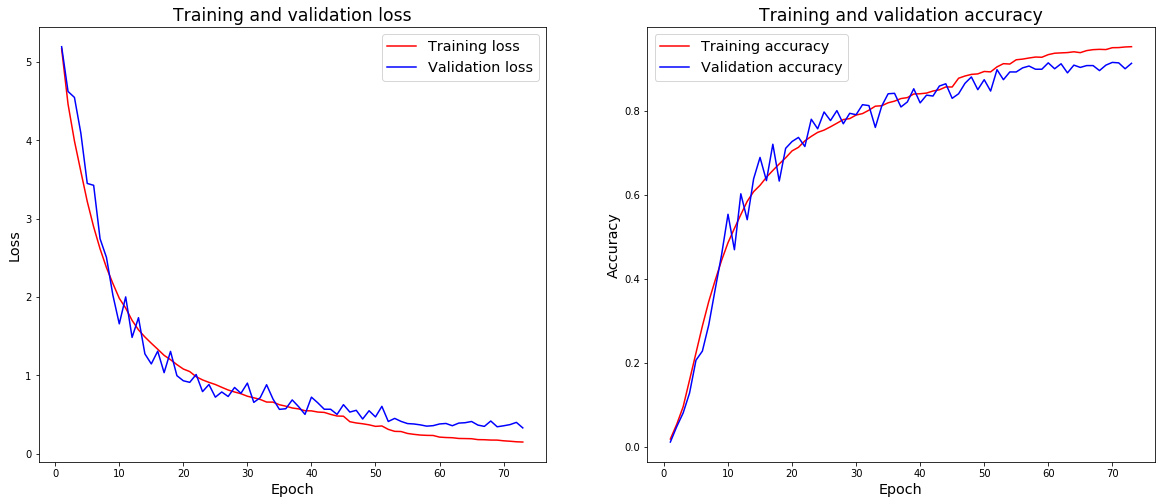

In [26]:
# plotting accuracy and loss

epoch_count = [i for i in range(1,(epoch)+1)]
plt.figure(figsize = (20,8))
plt.subplot(1,2,1)
plt.plot(epoch_count,train_loss,color = 'r',label = 'Training loss')
plt.plot(epoch_count,valid_loss,color = 'b',label = 'Validation loss')
plt.title('Training and validation loss',fontsize = 'xx-large')
plt.xlabel('Epoch',fontsize = 'x-large')
plt.ylabel('Loss',fontsize = 'x-large')
plt.legend(fontsize = 'x-large')
plt.subplot(1,2,2)
plt.plot(epoch_count,train_accuracy,color = 'r',label = 'Training accuracy')
plt.plot(epoch_count,valid_accuracy,color = 'b',label = 'Validation accuracy')
plt.title('Training and validation accuracy',fontsize = 'xx-large')
plt.xlabel('Epoch',fontsize = 'x-large')
plt.ylabel('Accuracy',fontsize = 'x-large')
plt.legend(fontsize = 'x-large')
plt.savefig('D:\\download\\100 bird species\\model4_copy3.jpg',quality = 200)
plt.show()


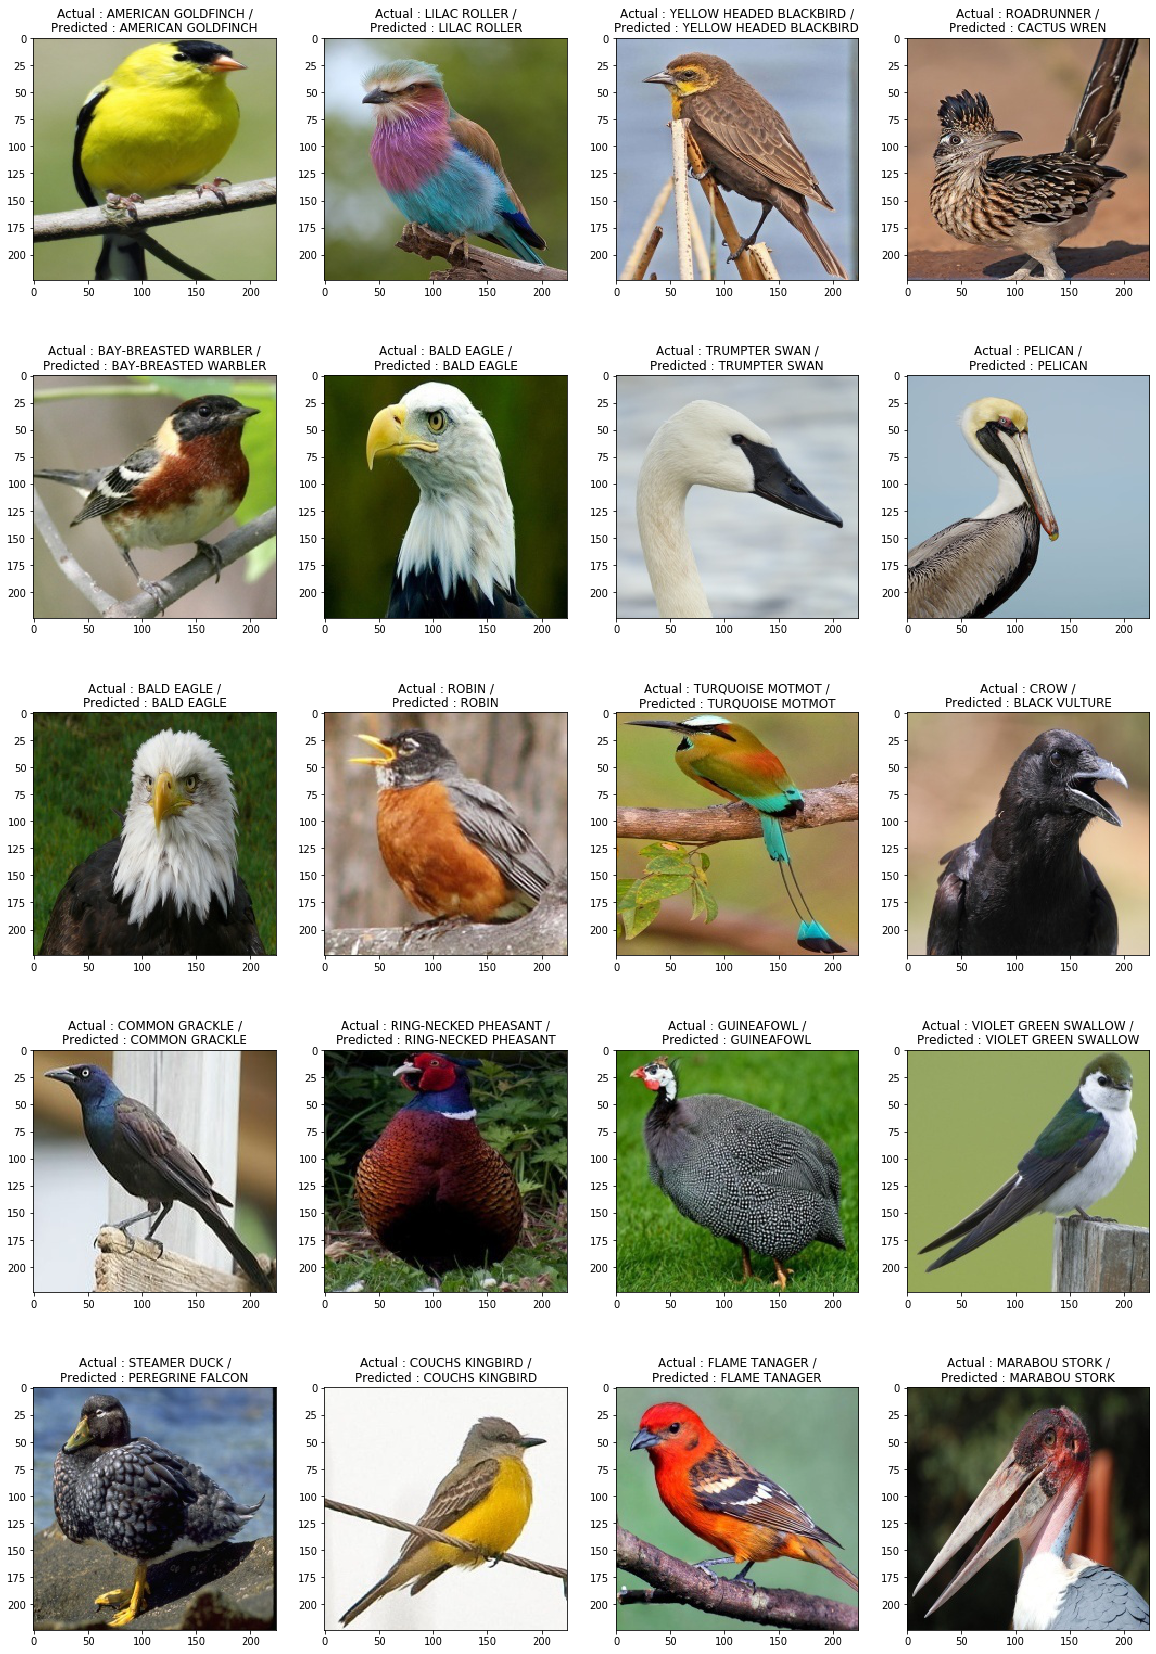

In [27]:
# showing same predicted result in title with ploting actual image
from matplotlib import image
import random
plt.figure(figsize=(20,30))
for i in range(20):
    species = os.listdir(test_dir)[random.randint(0,184)]
    path = os.path.join(test_dir,species)
    img_label = os.listdir(path)[random.randint(0,4)]
    path = os.path.join(path,img_label)
    img = np.array(image.imread(path))/255
    pred = np.argmax(model4.predict(img.reshape(1,224,224,3)))
    pred_species = code_label[pred]
    plt.subplot(5,4,i+1)
    plt.imshow(img)
    plt.title(f'Actual : {species} /\nPredicted : {pred_species}')

plt.show()

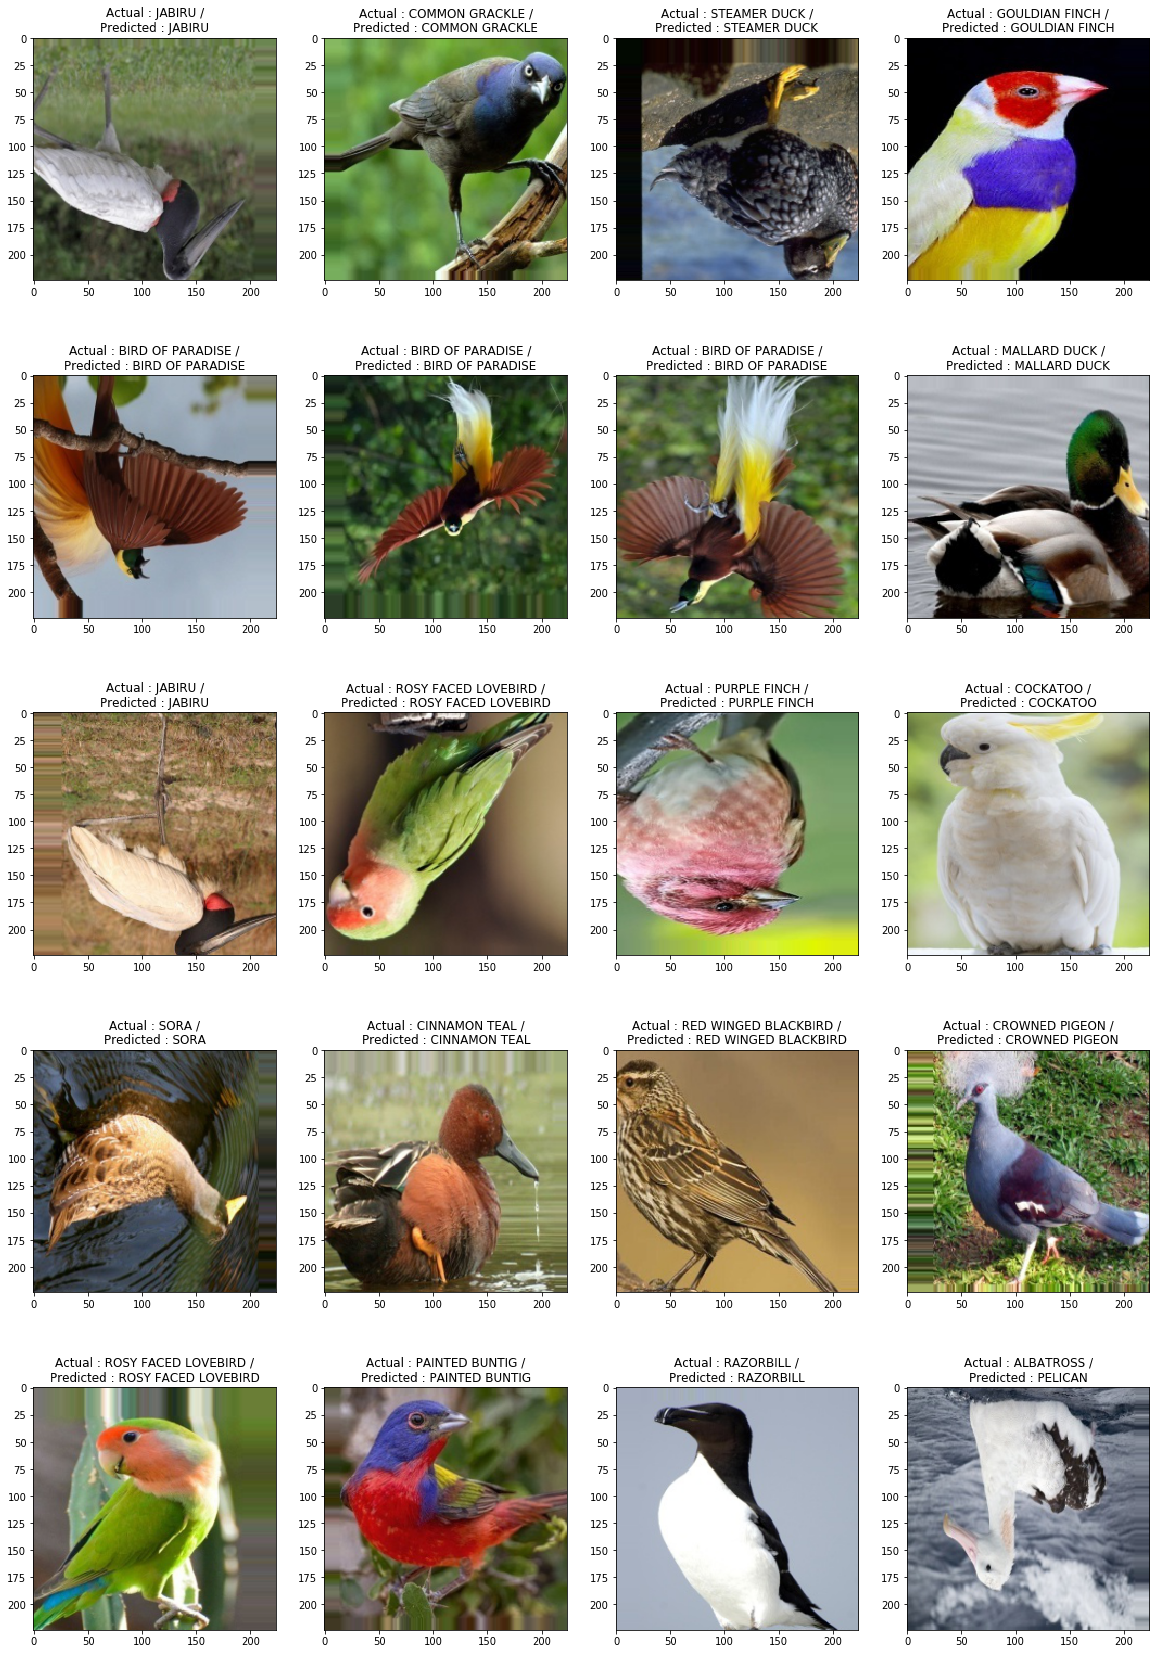

In [44]:
# plotting some prdiction from test genrator

from matplotlib import image
import random
plt.figure(figsize=(20,30))
for i in range(20):
    a = random.randint(0,13)
    b = random.randint(0,63)
    species = classes[(test_data[a][1][b]).argmax()]
    img = test_data[a][0][b]
    pred = np.argmax(model4.predict(img.reshape(1,224,224,3)))
    pred_species = classes[pred]
    plt.subplot(5,4,i+1)
    plt.imshow((img*255).astype(np.uint8))
    plt.title(f'Actual : {species} /\nPredicted : {pred_species}')

plt.show()

In [41]:

from sklearn.metrics import classification_report


predictions = model4.predict(test_data)
predicted_classes = np.argmax(predictions, axis=-1)
true_classes = test_data.classes
class_labels = list(test_data.class_indices.keys())

report = classification_report(true_classes, predicted_classes, 
                               target_names = class_labels,
                               digits = 2,output_dict = True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv('D:\\download\\100 bird species\\bird_model4_copy3.csv')
report_df

,precision,recall,f1-score,support
ALBATROSS,0.750000,0.600000,0.666667,5.000000
ALEXANDRINE PARAKEET,0.666667,0.800000,0.727273,5.000000
AMERICAN AVOCET,1.000000,1.000000,1.000000,5.000000
AMERICAN BITTERN,1.000000,1.000000,1.000000,5.000000
AMERICAN COOT,1.000000,0.800000,0.888889,5.000000
...,...,...,...,...
WOOD DUCK,1.000000,1.000000,1.000000,5.000000
YELLOW HEADED BLACKBIRD,1.000000,0.800000,0.888889,5.000000
accuracy,0.897297,0.897297,0.897297,0.897297
macro avg,0.911431,0.897297,0.892834,925.000000


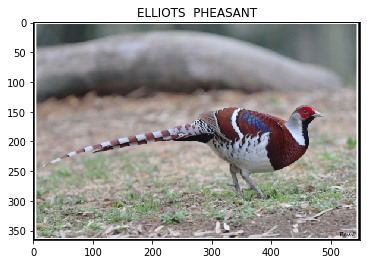

In [57]:
# Load the image

import matplotlib as m
import cv2
from PIL import Image
import requests
from io import BytesIO

# some bird url from google to check model preiction
# Razorbill : 'https://encrypted-tbn0.gstatic.com/images?q=tbn%3AANd9GcT-BWaNju76a-2FDIcQtO1dvFzRy30K0oaHyDYmVJlJRop1kO7G&usqp=CAU'
# Elliots Pheasant : https://www.birdforum.net/opus/images/thumb/1/1e/IMG_1237g.jpg/550px-IMG_1237g.jpg

response = requests.get('https://www.birdforum.net/opus/images/thumb/1/1e/IMG_1237g.jpg/550px-IMG_1237g.jpg')


img = np.asarray(Image.open(BytesIO(response.content)))

# below one is downloaded in hard-drive and then checked

#img = m.image.imread('test1.jpg')

plt.imshow(img)

# We resize the image to the input width and height of the first layer of the network.
resized_image = cv2.resize(img, (224, 224))
title = code_label[np.argmax(model4.predict((resized_image.reshape(1,224,224,3))/255))]
plt.title(title)
plt.show()



In [28]:
tf.keras.utils.plot_model(
    model4, to_file='D:\\download\\100 bird species\\model4_copy3_plot.png', show_shapes=True, show_layer_names=True,
    rankdir='TB', expand_nested=False, dpi=500
)